# 3. Combined results

This notebook reads the results from Notebook 1. It shows the return from the combined signals. It also shows the signal coefficients and model weights. All return charts use cumulative log returns.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA = Path('dataset')
returns = pd.read_parquet(DATA / 'final_returns.parquet')
returns['date'] = pd.to_datetime(returns['date'])
plt.rcParams.update({'figure.figsize': (11, 5), 'axes.spines.top': False,
                     'axes.spines.right': False})

def log_path(frame, field):
    # Add the log of each daily growth value.
    values = frame.sort_values('date')[field].to_numpy()
    assert np.all(values > -1)
    return np.cumsum(np.log1p(values))

def active_log_path(frame):
    # Compare total growth with benchmark growth on each date.
    frame = frame.sort_values('date')
    return np.cumsum(np.log1p(frame['portfolio_return'].to_numpy())
                     - np.log1p(frame['benchmark_return'].to_numpy()))


## 3.1 Why combine signals?

Two useful signals can help at different times. A combination can reduce changes in return if the signals do not have the same losses at the same times. A combination can also have a lower return than the best signal. We therefore test equal weights and three rules that change the signal coefficients with known past data.

## 3.2 Time-decay ridge rules

Each ridge rule gives less weight to older stock results. A half-life is the number of trade days after which a past result gets half its first weight. The half-lives are 63, 252, and 1,260 trade days. The common prior for both signal coefficients is 0.00001. This prior says to start with equal positive coefficients. The fit can move each coefficient when the data support a change.

Short windows can respond fast, but their estimates can change sharply. Long windows use more data, but they can respond slowly. The 63-day rule uses penalty 18 to limit sharp changes. The 252-day rule uses penalty 5. The 1,260-day rule uses penalty 2.5 because it has more history. These values are fixed test choices. They do not prove that one rule is best in new data.

## 3.3 Bayesian model averaging

The fourth rule gives the two standardized signals equal weight. Bayesian model averaging (BMA) gives a weight to this rule and to each ridge rule. Each rule starts with a weight of 0.25. The code adds known active portfolio returns for each rule. It multiplies that sum by 16 and then uses a softmax function. This function makes four positive weights that add to one. This is an exponential return-based model update. It is not a full probability model for stock returns. It uses the same model weights to make the long-only combined portfolio. A model weight is not a stock weight.

## 3.4 Active returns

This chart compares the four combination rules and BMA. It shows returns relative to the benchmark. These portfolios can hold short stock positions.

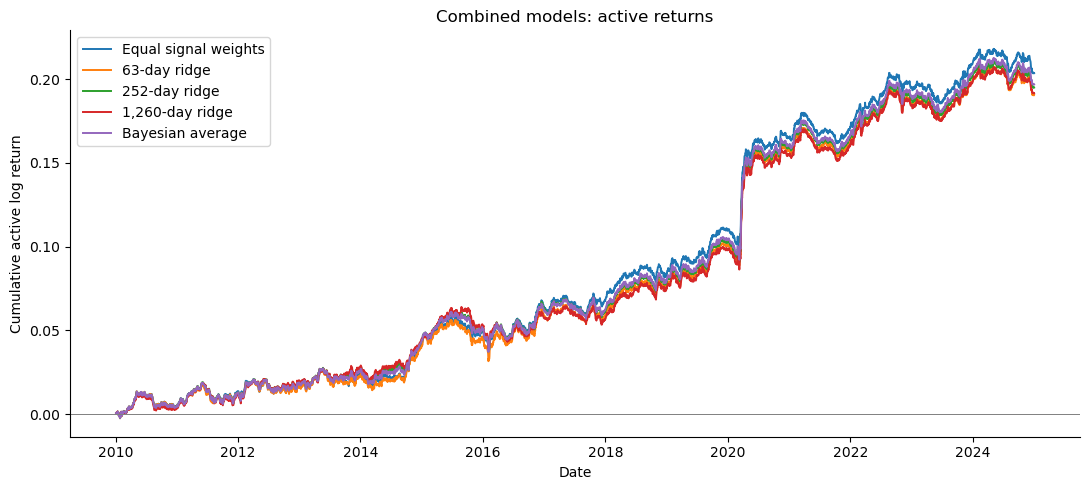

In [2]:
# Show returns for the same set of trade dates.
labels = {'equal_weight_active': 'Equal signal weights', 'ridge_63_p18_active': '63-day ridge', 'ridge_252_p5_active': '252-day ridge', 'ridge_1260_p2.5_active': '1,260-day ridge', 'bayesian_active': 'Bayesian average'}
fig, ax = plt.subplots()
for key, label in labels.items():
    day = returns.loc[returns['portfolio'] == key].sort_values('date')
    values = log_path(day, 'portfolio_return') if False else active_log_path(day)
    ax.plot(day['date'], values, label=label, linewidth=1.4)
ax.axhline(0, color='gray', linewidth=0.7)
ax.set_title('Combined models: active returns')
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative log return' if False else 'Cumulative active log return')
ax.legend()
plt.tight_layout()
plt.show()


## 3.5 Total returns

The first chart shows total returns for the combined long-short portfolios. The second chart shows the long-only BMA portfolio and the benchmark. The ridge rules and equal-weight rule were tested as active portfolios. Their model weights also make the long-only BMA portfolio.

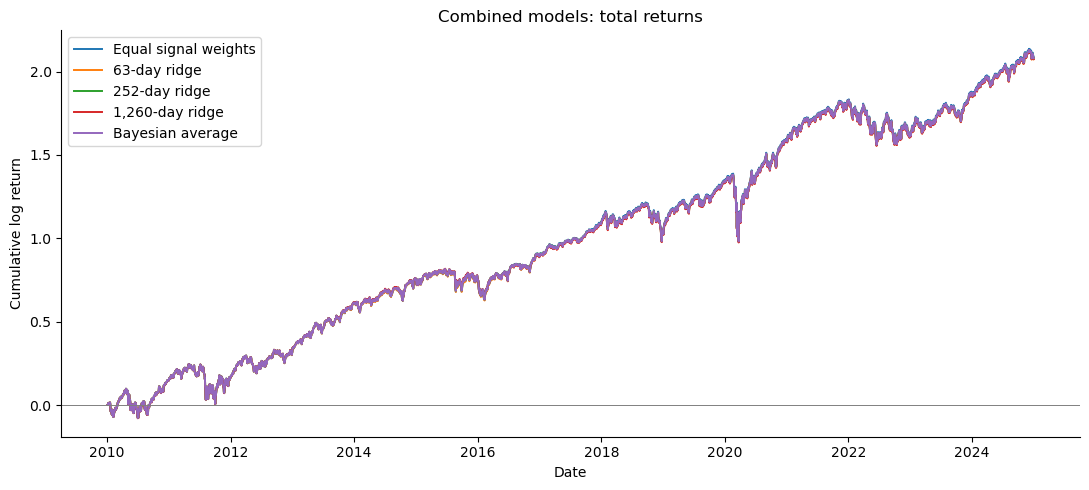

In [3]:
# Show returns for the same set of trade dates.
labels = {'equal_weight_active': 'Equal signal weights', 'ridge_63_p18_active': '63-day ridge', 'ridge_252_p5_active': '252-day ridge', 'ridge_1260_p2.5_active': '1,260-day ridge', 'bayesian_active': 'Bayesian average'}
fig, ax = plt.subplots()
for key, label in labels.items():
    day = returns.loc[returns['portfolio'] == key].sort_values('date')
    values = log_path(day, 'portfolio_return') if True else active_log_path(day)
    ax.plot(day['date'], values, label=label, linewidth=1.4)
ax.axhline(0, color='gray', linewidth=0.7)
ax.set_title('Combined models: total returns')
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative log return' if True else 'Cumulative active log return')
ax.legend()
plt.tight_layout()
plt.show()


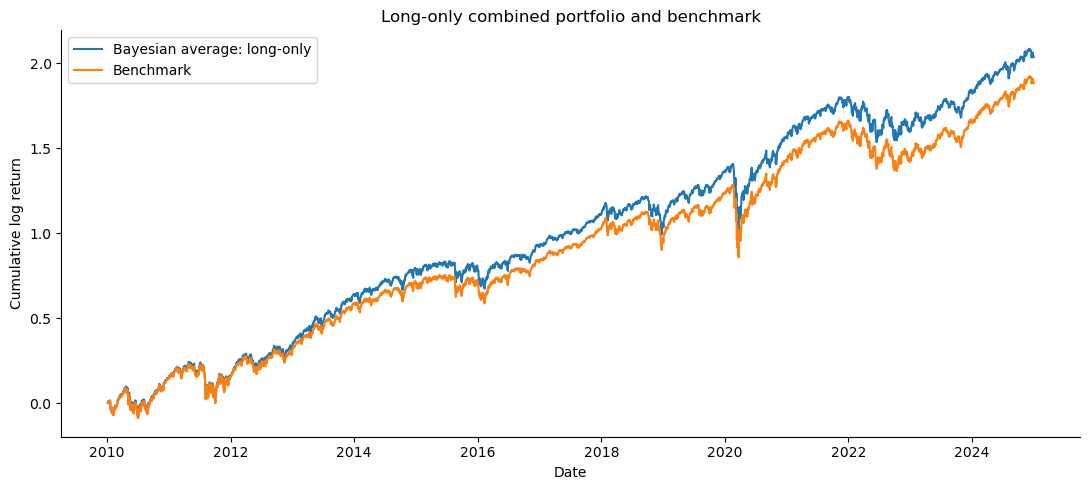

In [4]:
group = returns.loc[returns['portfolio'] == 'bayesian_long_only'].sort_values('date')
fig, ax = plt.subplots()
ax.plot(group['date'], log_path(group, 'portfolio_return'), label='Bayesian average: long-only')
ax.plot(group['date'], log_path(group, 'benchmark_return'), label='Benchmark')
ax.set_title('Long-only combined portfolio and benchmark')
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative log return')
ax.legend()
plt.tight_layout()
plt.show()


## 3.6 Ridge signal coefficients

Each line shows one fitted coefficient. A positive value raises a stock score. A negative value lowers it. The chart uses units of 0.00001, so a value of one is the common prior of 0.00001. The two signals can have different coefficient sizes because the model first puts each stock score on a common scale.

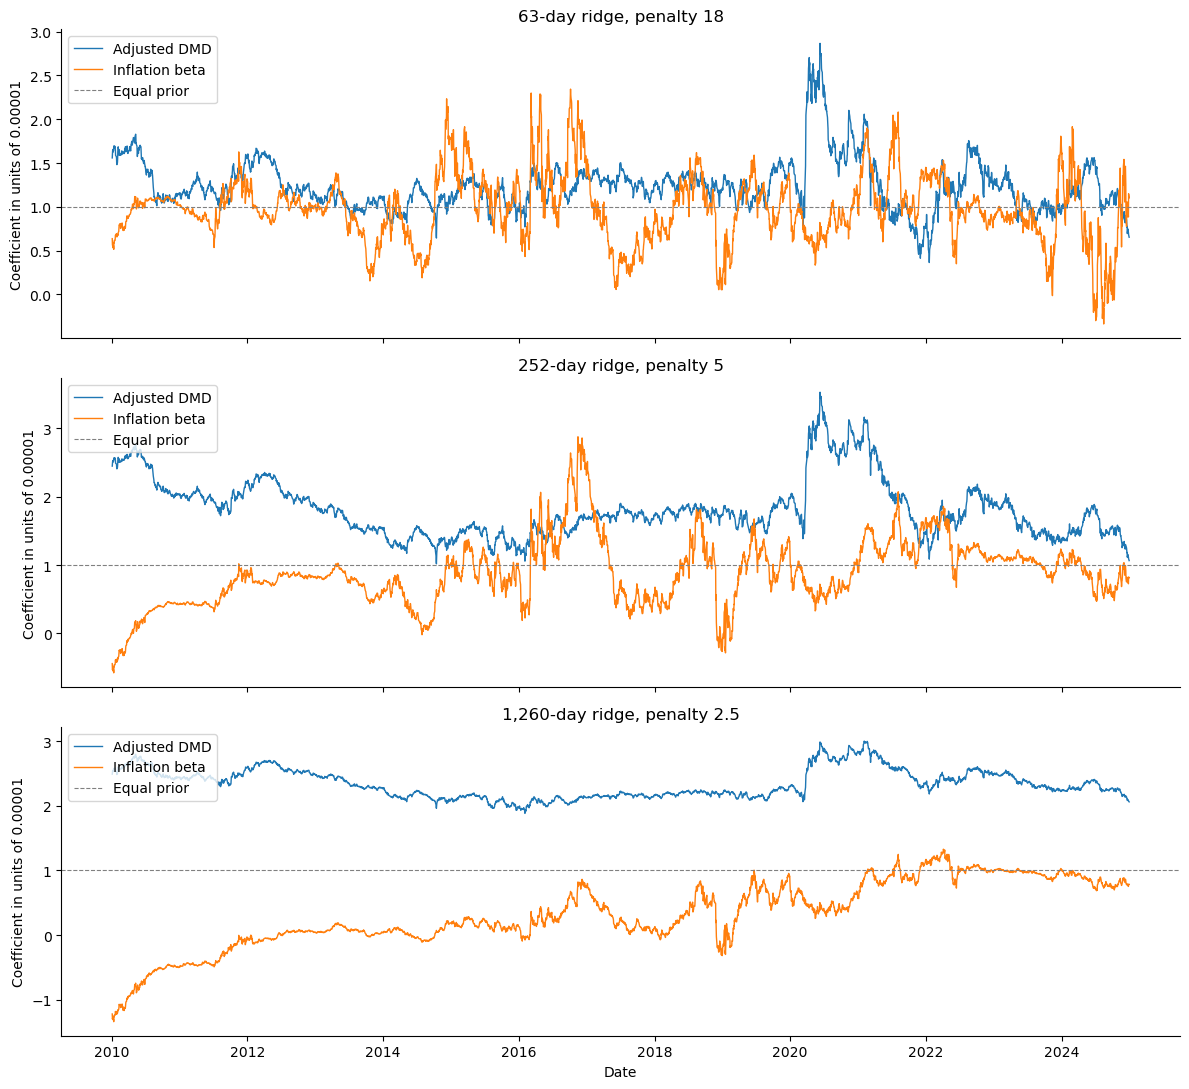

In [5]:
coefficients = pd.read_parquet(DATA / 'final_coefficients.parquet')
coefficients['date'] = pd.to_datetime(coefficients['date'])
methods = [('ridge_63_p18','63-day ridge, penalty 18'),
           ('ridge_252_p5','252-day ridge, penalty 5'),
           ('ridge_1260_p2.5','1,260-day ridge, penalty 2.5')]
fig, axes = plt.subplots(3, 1, figsize=(12, 11), sharex=True)
for ax, (key, name) in zip(axes, methods):
    group = coefficients.loc[coefficients['method'] == key].sort_values('date')
    ax.plot(group['date'], group['dmd'] / 1e-5, label='Adjusted DMD', linewidth=1)
    ax.plot(group['date'], group['inflation_beta'] / 1e-5, label='Inflation beta', linewidth=1)
    ax.axhline(1, color='gray', linestyle='--', linewidth=0.8, label='Equal prior')
    ax.set_title(name)
    ax.set_ylabel('Coefficient in units of 0.00001')
    ax.legend(loc='upper left')
axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.show()


## 3.7 Weight on each combination rule

The chart shows how BMA divides its weight among the four rules. At each date, the four weights add to one. These weights come from past active portfolio returns. The long-only combined portfolio uses these same four weights.

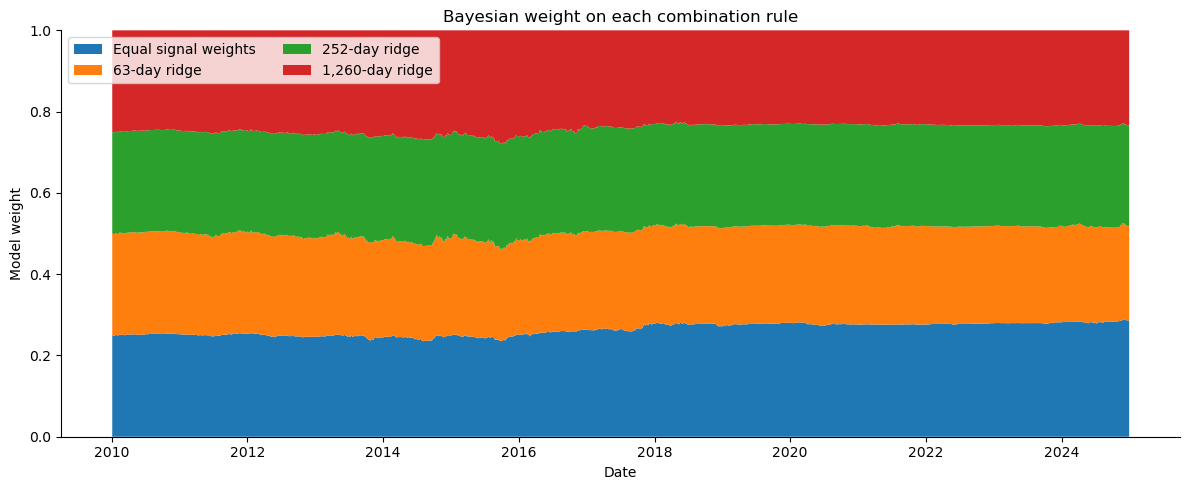

In [6]:
weights = pd.read_parquet(DATA / 'final_model_weights.parquet')
weights = weights.loc[weights['variant'] == 'active'].sort_values('date')
weights['date'] = pd.to_datetime(weights['date'])
fields = ['equal_weight', 'ridge_63_p18', 'ridge_252_p5', 'ridge_1260_p2.5']
labels = ['Equal signal weights', '63-day ridge', '252-day ridge', '1,260-day ridge']
fig, ax = plt.subplots(figsize=(12, 5))
ax.stackplot(weights['date'], *[weights[field] for field in fields], labels=labels)
ax.set_title('Bayesian weight on each combination rule')
ax.set_xlabel('Date')
ax.set_ylabel('Model weight')
ax.set_ylim(0, 1)
ax.legend(loc='upper left', ncol=2)
plt.tight_layout()
plt.show()


## 3.8 Return and risk table

The table uses active returns for the long-short portfolios. It uses total returns for the long-only portfolio. Forecast tracking error is an annual risk estimate. The backtest is gross of trade costs.

In [7]:
combined = {'equal_weight_active':'Equal signal weights: long-short',
            'ridge_63_p18_active':'63-day ridge: long-short',
            'ridge_252_p5_active':'252-day ridge: long-short',
            'ridge_1260_p2.5_active':'1,260-day ridge: long-short',
            'bayesian_active':'Bayesian average: long-short',
            'bayesian_long_only':'Bayesian average: long-only'}
rows = []
for key, label in combined.items():
    group = returns.loc[returns['portfolio'] == key]
    values = (group['portfolio_return'] - group['benchmark_return']
              if key.endswith('_active') else group['portfolio_return'])
    rows.append({'Portfolio':label, 'Annual mean return':252 * values.mean(),
                 'Annual volatility':np.sqrt(252) * values.std(ddof=1),
                 'Sharpe ratio':np.sqrt(252) * values.mean() / values.std(ddof=1),
                 'Highest forecast tracking error':group['predicted_te'].max(),
                 'Largest absolute active beta':group['active_beta'].abs().max(),
                 'Lowest stock weight':group['minimum_total_weight'].min()})
display(pd.DataFrame(rows).set_index('Portfolio').style.format({
    'Annual mean return':'{:.2%}', 'Annual volatility':'{:.2%}',
    'Sharpe ratio':'{:.2f}', 'Highest forecast tracking error':'{:.2%}',
    'Largest absolute active beta':'{:.2g}', 'Lowest stock weight':'{:.4f}'}))


,Annual mean return,Annual volatility,Sharpe ratio,Highest forecast tracking error,Largest absolute active beta,Lowest stock weight
Portfolio,,,,,,
Equal signal weights: long-short,1.40%,1.32%,1.06,1.00%,3.7e-16,-0.0247
63-day ridge: long-short,1.31%,1.33%,0.99,1.00%,3.5e-16,-0.0274
252-day ridge: long-short,1.34%,1.32%,1.02,1.00%,3.3e-16,-0.0273
"1,260-day ridge: long-short",1.32%,1.31%,1.00,1.00%,3.3e-16,-0.0276
Bayesian average: long-short,1.35%,1.32%,1.03,1.00%,4.3e-16,-0.0272
Bayesian average: long-only,15.21%,17.87%,0.85,1.00%,4.9e-16,-0.0000
